# EDA — 02. Análisis de Variables Target

**Proyecto Final — Uplift Modeling | CAECE**

---

## Objetivo

Análisis completo de los tres outcomes del experimento:
- `visit` — binario: ¿visitó el sitio en las 2 semanas post-envío?
- `conversion` — binario: ¿realizó una compra?
- `spend` — continuo: ¿cuánto gastó (USD)?

Se estudian distribuciones individuales, la jerarquía lógica que los vincula y el efecto bruto
de los grupos de tratamiento sobre cada outcome.

---

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats

warnings.filterwarnings("ignore")
try:    plt.style.use("seaborn-v0_8-whitegrid")
except: plt.style.use("seaborn-whitegrid")
sns.set_palette("Set2")
PALETTE = sns.color_palette("Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)

df = pd.read_csv(os.path.join("..", "..", "data", "raw", "hillstrom.csv"))
print(f"Dataset: {df.shape[0]:,} filas × {df.shape[1]} columnas")

Dataset: 64,000 filas × 12 columnas


## 1. Resumen de los Tres Targets

In [2]:
overview = pd.DataFrame([
    {"Target":"visit",      "Tipo":"Binario",      "Tarea ML":"Clasificación",
     "N positivos":f"{df['visit'].sum():,}",      "% positivos":f"{df['visit'].mean()*100:.2f}%",
     "Descripción":"Visitó el sitio en 2 semanas post-envío"},
    {"Target":"conversion", "Tipo":"Binario",      "Tarea ML":"Clasificación",
     "N positivos":f"{df['conversion'].sum():,}", "% positivos":f"{df['conversion'].mean()*100:.2f}%",
     "Descripción":"Realizó una compra en 2 semanas post-envío"},
    {"Target":"spend",      "Tipo":"Continuo ≥ 0","Tarea ML":"Regresión",
     "N positivos":f"{(df['spend']>0).sum():,}  (spend>0)", "% positivos":f"{(df['spend']>0).mean()*100:.2f}%",
     "Descripción":"Gasto en USD en 2 semanas post-envío"},
])
display(overview.style.set_caption("Los tres targets del experimento").hide(axis="index"))

Target,Tipo,Tarea ML,N positivos,% positivos,Descripción
visit,Binario,Clasificación,"9,394",14.68%,Visitó el sitio en 2 semanas post-envío
conversion,Binario,Clasificación,578,0.90%,Realizó una compra en 2 semanas post-envío
spend,Continuo ≥ 0,Regresión,578 (spend>0),0.90%,Gasto en USD en 2 semanas post-envío


## 2. `visit` — Balance de Clases

visit = 0  : 54,606  (85.32%)
visit = 1  : 9,394  (14.68%)
Ratio      : 5.81:1  (no-visitó : visitó)


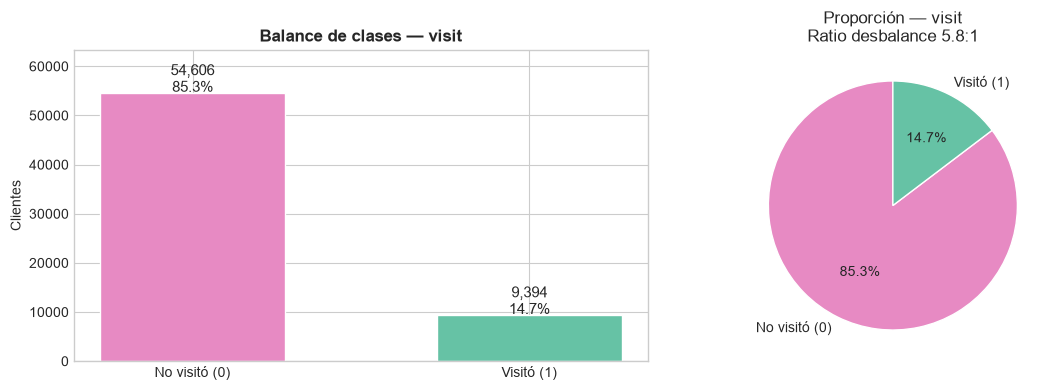

In [3]:
n_v0, n_v1 = int((df["visit"]==0).sum()), int(df["visit"].sum())
imb_v = n_v0 / n_v1

print(f"visit = 0  : {n_v0:,}  ({n_v0/len(df)*100:.2f}%)")
print(f"visit = 1  : {n_v1:,}  ({n_v1/len(df)*100:.2f}%)")
print(f"Ratio      : {imb_v:.2f}:1  (no-visitó : visitó)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Bar chart
axes[0].bar(["No visitó (0)", "Visitó (1)"], [n_v0, n_v1],
            color=[PALETTE[3], PALETTE[0]], edgecolor="white", width=0.55)
for i, v in enumerate([n_v0, n_v1]):
    axes[0].text(i, v + 200, f"{v:,}\n{v/len(df)*100:.1f}%", ha="center", fontsize=11)
axes[0].set_title("Balance de clases — visit", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Clientes")
axes[0].set_ylim(0, max(n_v0, n_v1) * 1.16)

# Pie chart
axes[1].pie([n_v0, n_v1], labels=["No visitó (0)", "Visitó (1)"],
            colors=[PALETTE[3], PALETTE[0]], autopct="%1.1f%%",
            startangle=90, wedgeprops={"edgecolor":"white"})
axes[1].set_title(f"Proporción — visit\nRatio desbalance {imb_v:.1f}:1", fontsize=12)
plt.tight_layout()
plt.show()

## 3. `conversion` — Balance de Clases

conversion = 0 : 63,422  (99.10%)
conversion = 1 : 578  (0.90%)
Ratio           : 109.7:1
P(conv | visit=1): 6.15%  — de 9,394 visitantes, convirtieron 578


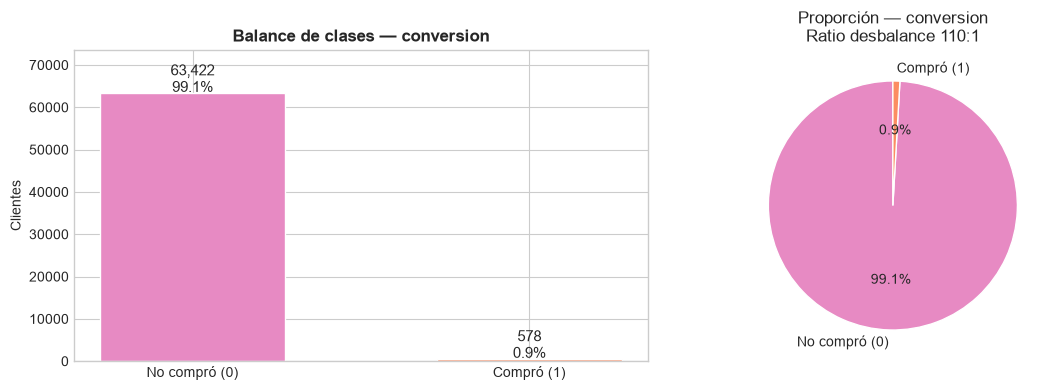

In [4]:
n_c0, n_c1 = int((df["conversion"]==0).sum()), int(df["conversion"].sum())
imb_c = n_c0 / n_c1
n_vis = int(df["visit"].sum())
conv_dado_visit = df[df["visit"]==1]["conversion"].mean()

print(f"conversion = 0 : {n_c0:,}  ({n_c0/len(df)*100:.2f}%)")
print(f"conversion = 1 : {n_c1:,}  ({n_c1/len(df)*100:.2f}%)")
print(f"Ratio           : {imb_c:.1f}:1")
print(f"P(conv | visit=1): {conv_dado_visit*100:.2f}%  — de {n_vis:,} visitantes, convirtieron {n_c1:,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["No compró (0)", "Compró (1)"], [n_c0, n_c1],
            color=[PALETTE[3], PALETTE[1]], edgecolor="white", width=0.55)
for i, v in enumerate([n_c0, n_c1]):
    axes[0].text(i, v + 200, f"{v:,}\n{v/len(df)*100:.1f}%", ha="center", fontsize=11)
axes[0].set_title("Balance de clases — conversion", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Clientes")
axes[0].set_ylim(0, max(n_c0, n_c1) * 1.16)

axes[1].pie([n_c0, n_c1], labels=["No compró (0)", "Compró (1)"],
            colors=[PALETTE[3], PALETTE[1]], autopct="%1.1f%%",
            startangle=90, wedgeprops={"edgecolor":"white"})
axes[1].set_title(f"Proporción — conversion\nRatio desbalance {imb_c:.0f}:1", fontsize=12)
plt.tight_layout()
plt.show()

In [5]:
# Comparación de métricas de desbalance
desequil = pd.DataFrame([
    {"Target":"visit",      "N_0":n_v0, "N_1":n_v1,
     "% clase positiva":f"{n_v1/len(df)*100:.2f}%",
     "Imbalance ratio":f"{n_v0/n_v1:.1f}:1",
     "Severidad": "Moderado" if n_v0/n_v1 < 5 else "Severo"},
    {"Target":"conversion", "N_0":n_c0, "N_1":n_c1,
     "% clase positiva":f"{n_c1/len(df)*100:.2f}%",
     "Imbalance ratio":f"{n_c0/n_c1:.1f}:1",
     "Severidad": "Moderado" if n_c0/n_c1 < 5 else "Severo"},
])
display(desequil.style
    .set_caption("Resumen de desbalance — targets binarios")
    .hide(axis="index")
    .format({"N_0":"{:,}","N_1":"{:,}"})
)

Target,N_0,N_1,% clase positiva,Imbalance ratio,Severidad
visit,"54,606","9,394",14.68%,5.8:1,Severo
conversion,"63,422",578,0.90%,109.7:1,Severo


## 4. `spend` — Variable Continua Zero-Inflated

In [6]:
spend_nz = df.loc[df["spend"] > 0, "spend"]
n_zero   = int((df["spend"] == 0).sum())
n_pos    = int((df["spend"] > 0).sum())

print("SPEND — análisis completo")
print(f"{'─'*55}")
print(f"  spend = 0  : {n_zero:,}  ({n_zero/len(df)*100:.2f}%)")
print(f"  spend > 0  : {n_pos:,}   ({n_pos/len(df)*100:.2f}%)")
print()
print("Distribución de spend > 0:")
print(f"  Mínimo   : ${spend_nz.min():.2f}")
print(f"  Q25      : ${spend_nz.quantile(0.25):.2f}")
print(f"  Mediana  : ${spend_nz.median():.2f}")
print(f"  Media    : ${spend_nz.mean():.2f}")
print(f"  Q75      : ${spend_nz.quantile(0.75):.2f}")
print(f"  Máximo   : ${spend_nz.max():,.2f}")
print(f"  Skewness : {spend_nz.skew():.3f}")
print(f"  Kurtosis : {spend_nz.kurtosis():.3f}")

SPEND — análisis completo
───────────────────────────────────────────────────────
  spend = 0  : 63,422  (99.10%)
  spend > 0  : 578   (0.90%)

Distribución de spend > 0:
  Mínimo   : $29.99
  Q25      : $32.27
  Mediana  : $80.80
  Media    : $116.36
  Q75      : $153.35
  Máximo   : $499.00
  Skewness : 1.761
  Kurtosis : 2.898


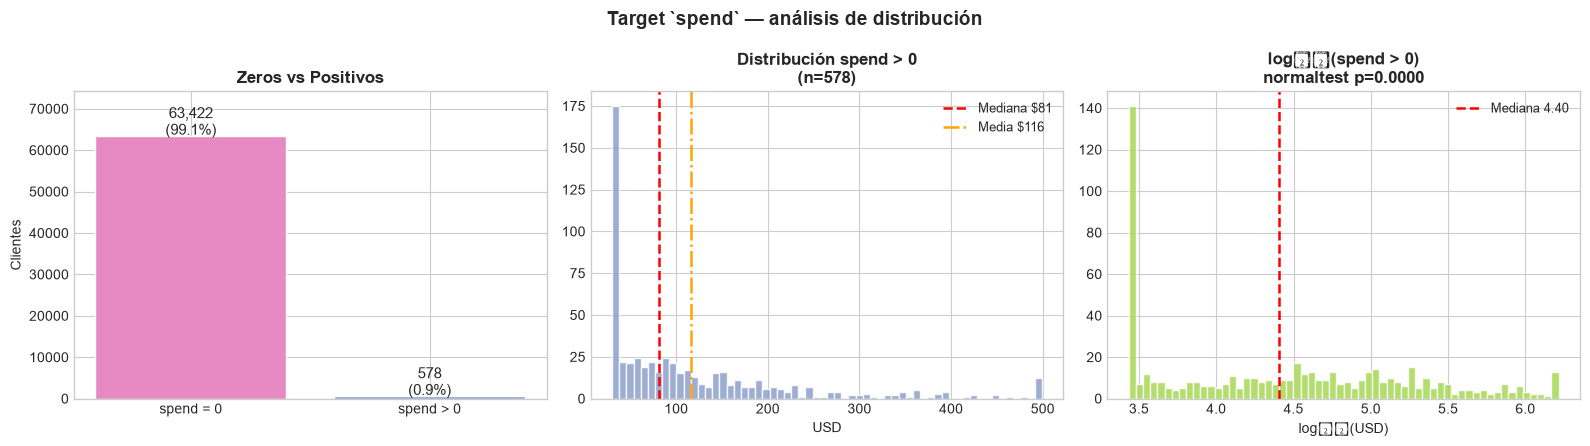

→ log₁₊ NO normaliza completamente (p=0.0000)
→ Skewness de spend_nz = 1.76 — distribución muy asimétrica a la derecha.


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1) Zeros vs positivos
axes[0].bar(["spend = 0", "spend > 0"], [n_zero, n_pos],
            color=[PALETTE[3], PALETTE[2]], edgecolor="white")
for i, v in enumerate([n_zero, n_pos]):
    axes[0].text(i, v + 300, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center", fontsize=11)
axes[0].set_title("Zeros vs Positivos", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Clientes")
axes[0].set_ylim(0, max(n_zero, n_pos) * 1.17)

# 2) Distribución de spend > 0
axes[1].hist(spend_nz.values, bins=60, color=PALETTE[2], edgecolor="white", alpha=0.85)
axes[1].axvline(spend_nz.median(), color="red",    ls="--", lw=1.8, label=f"Mediana ${spend_nz.median():.0f}")
axes[1].axvline(spend_nz.mean(),   color="orange", ls="-.", lw=1.8, label=f"Media ${spend_nz.mean():.0f}")
axes[1].set_title(f"Distribución spend > 0\n(n={n_pos:,})", fontsize=12, fontweight="bold")
axes[1].set_xlabel("USD")
axes[1].legend(fontsize=9)

# 3) log1p(spend > 0)
log_sp = np.log1p(spend_nz.values)
_, pval_norm = stats.normaltest(log_sp)
axes[2].hist(log_sp, bins=60, color=PALETTE[4], edgecolor="white", alpha=0.85)
axes[2].axvline(np.median(log_sp), color="red", ls="--", lw=1.8, label=f"Mediana {np.median(log_sp):.2f}")
axes[2].set_title(f"log₁₊(spend > 0)\nnormaltest p={pval_norm:.4f}", fontsize=12, fontweight="bold")
axes[2].set_xlabel("log₁₊(USD)")
axes[2].legend(fontsize=9)

plt.suptitle("Target `spend` — análisis de distribución", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

print(f"→ log₁₊ {'aproxima normalidad' if pval_norm>0.05 else 'NO normaliza completamente'} (p={pval_norm:.4f})")
print(f"→ Skewness de spend_nz = {spend_nz.skew():.2f} — distribución muy asimétrica a la derecha.")

In [8]:
# Análisis de percentiles y cola de la distribución
pcts    = [50, 75, 90, 95, 99, 99.5]
pct_vals = np.percentile(spend_nz, pcts)

pct_df = pd.DataFrame({"Percentil":[f"P{p}" for p in pcts],
                        "Spend (USD)":[f"${v:,.2f}" for v in pct_vals]})
display(pct_df.style.set_caption("Percentiles — spend > 0").hide(axis="index"))

for umbral in [100, 250, 500, 1000]:
    n_above = (spend_nz > umbral).sum()
    print(f"  spend > ${umbral:,} : {n_above:,} clientes ({n_above/n_pos*100:.1f}% de compradores)")

Percentil,Spend (USD)
P50,$80.80
P75,$153.35
P90,$256.49
P95,$362.20
P99,$499.00
P99.5,$499.00


  spend > $100 : 234 clientes (40.5% de compradores)
  spend > $250 : 59 clientes (10.2% de compradores)
  spend > $500 : 0 clientes (0.0% de compradores)
  spend > $1,000 : 0 clientes (0.0% de compradores)


## 5. Jerarquía entre Targets — Funnel de Conversión

Etapa,N,% del total,% paso anterior
Total clientes,"64,000",100.00%,100.00%
Visitaron,"9,394",14.68%,14.68%
Convirtieron,578,0.90%,6.15%
Gasto > 0,578,0.90%,100.00%


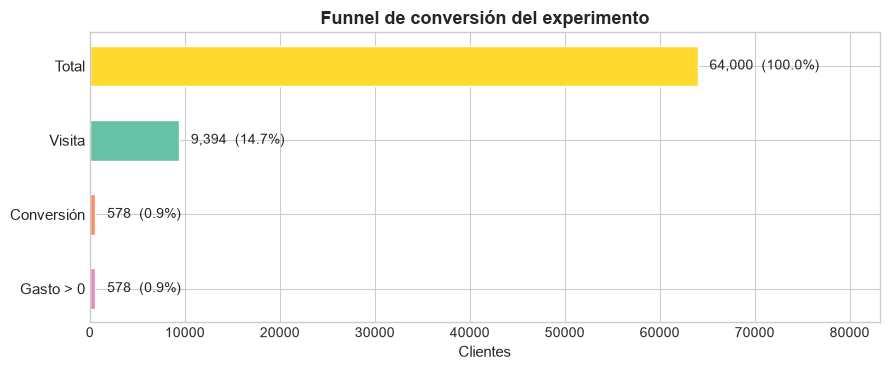

In [9]:
n_total = len(df)
n_vis2  = int(df["visit"].sum())
n_conv2 = int(df["conversion"].sum())
n_sp2   = int((df["spend"]>0).sum())

funnel = pd.DataFrame({
    "Etapa"              : ["Total clientes", "Visitaron", "Convirtieron", "Gasto > 0"],
    "N"                  : [n_total, n_vis2, n_conv2, n_sp2],
    "% del total"        : [100.0, n_vis2/n_total*100, n_conv2/n_total*100, n_sp2/n_total*100],
    "% paso anterior"    : [100.0, n_vis2/n_total*100, n_conv2/n_vis2*100, n_sp2/n_conv2*100],
})
display(funnel.style
    .format({"N":"{:,}","% del total":"{:.2f}%","% paso anterior":"{:.2f}%"})
    .set_caption("Funnel de conversión")
    .hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 3.8))
y_labels = ["Gasto > 0", "Conversión", "Visita", "Total"]
widths   = [n_sp2, n_conv2, n_vis2, n_total]
pcts_f   = [n_sp2/n_total*100, n_conv2/n_total*100, n_vis2/n_total*100, 100.0]
colors_f = [PALETTE[3], PALETTE[1], PALETTE[0], PALETTE[5]]
for y, (lbl, w, p, c) in enumerate(zip(y_labels, widths, pcts_f, colors_f)):
    ax.barh(y, w, color=c, edgecolor="white", height=0.55)
    ax.text(w + 400, y, f"  {w:,}  ({p:.1f}%)", va="center", fontsize=10)
ax.set_yticks(range(4))
ax.set_yticklabels(y_labels, fontsize=11)
ax.set_xlabel("Clientes", fontsize=11)
ax.set_title("Funnel de conversión del experimento", fontsize=13, fontweight="bold")
ax.set_xlim(0, n_total * 1.3)
plt.tight_layout()
plt.show()

In [10]:
# Combinaciones de targets — verificación de la jerarquía
combos = {
    "visit=0, conv=0, spend=0 (no interactuó)":
        ((df["visit"]==0)&(df["conversion"]==0)&(df["spend"]==0)).sum(),
    "visit=1, conv=0, spend=0 (visitó sin comprar)":
        ((df["visit"]==1)&(df["conversion"]==0)&(df["spend"]==0)).sum(),
    "visit=1, conv=1, spend>0 (visitó, compró, gastó)":
        ((df["visit"]==1)&(df["conversion"]==1)&(df["spend"]>0)).sum(),
}
for label, n in combos.items():
    print(f"  {label}: {n:,}  ({n/len(df)*100:.2f}%)")
total_combos = sum(combos.values())
print(f"\n  Total verificado: {total_combos:,}  ({total_combos/len(df)*100:.2f}%)")
if total_combos == len(df):
    print("  → La jerarquía lógica es perfectamente consistente ✓")

  visit=0, conv=0, spend=0 (no interactuó): 54,606  (85.32%)
  visit=1, conv=0, spend=0 (visitó sin comprar): 8,816  (13.78%)
  visit=1, conv=1, spend>0 (visitó, compró, gastó): 578  (0.90%)

  Total verificado: 64,000  (100.00%)
  → La jerarquía lógica es perfectamente consistente ✓


## 6. Targets por Grupo de Tratamiento — Efecto Bruto del Email

In [11]:
seg_agg = df.groupby("segment").agg(
    N              = ("visit",      "count"),
    visit_rate     = ("visit",      "mean"),
    conv_rate      = ("conversion", "mean"),
    spend_mean     = ("spend",      "mean"),
    spend_nz_mean  = ("spend",      lambda x: x[x>0].mean()),
    n_compradores  = ("conversion", "sum"),
).reset_index()

for col in ["visit_rate","conv_rate"]:
    seg_agg[col+"_%"] = (seg_agg[col]*100).round(4)
seg_agg["spend_mean_$"]    = seg_agg["spend_mean"].round(4)
seg_agg["spend_nz_mean_$"] = seg_agg["spend_nz_mean"].round(2)

display_cols = ["segment","N","visit_rate_%","conv_rate_%","spend_mean_$","spend_nz_mean_$","n_compradores"]
display(seg_agg[display_cols].style
    .set_caption("Outcomes por grupo de tratamiento — efecto bruto (ATE crudo)")
    .hide(axis="index")
    .format({"N":"{:,}","n_compradores":"{:,}"})
)

segment,N,visit_rate_%,conv_rate_%,spend_mean_$,spend_nz_mean_$,n_compradores
Mens E-Mail,"21,307",18.275700,1.253100,1.422600,113.530000,267
No E-Mail,"21,306",10.616700,0.572600,0.652800,114.000000,122
Womens E-Mail,"21,387",15.140000,0.883700,1.077200,121.890000,189


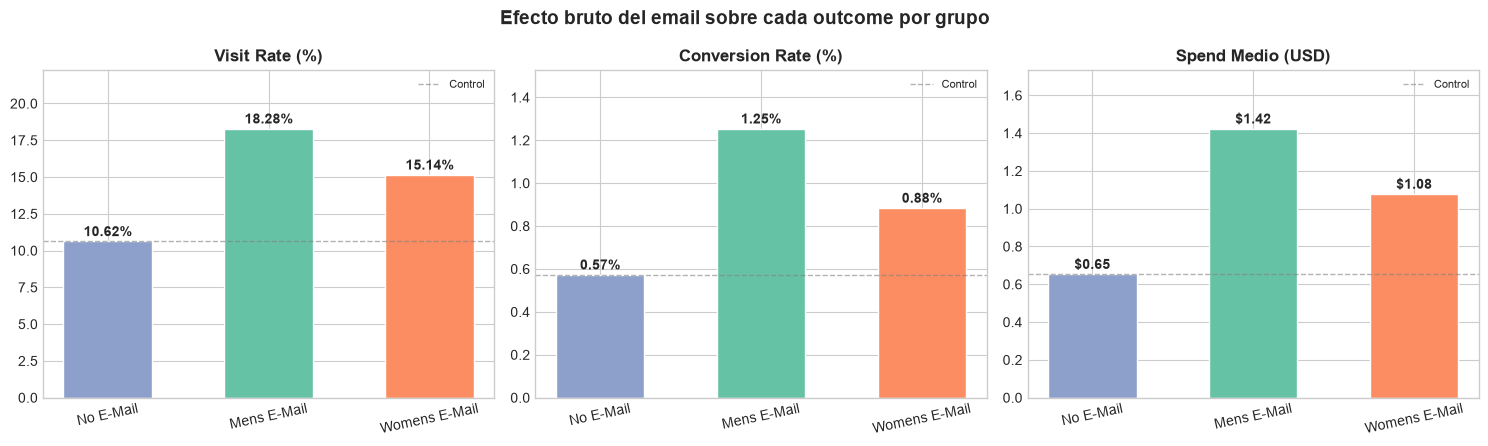

In [12]:
ORDER = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
seg_p = seg_agg.set_index("segment").reindex(ORDER)
colors_seg = [PALETTE[2], PALETTE[0], PALETTE[1]]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, col, lbl, fmt in zip(
    axes,
    ["visit_rate_%", "conv_rate_%", "spend_mean_$"],
    ["Visit Rate (%)", "Conversion Rate (%)", "Spend Medio (USD)"],
    ["{:.2f}%", "{:.2f}%", "${:.2f}"]
):
    vals = seg_p[col].values
    bars = ax.bar(ORDER, vals, color=colors_seg, edgecolor="white", width=0.55)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(vals)*0.02,
                fmt.format(v), ha="center", fontsize=10, fontweight="bold")
    ax.set_title(lbl, fontsize=12, fontweight="bold")
    ax.set_ylim(0, max(vals) * 1.22)
    ax.tick_params(axis="x", rotation=12)
    ax.axhline(vals[0], color="gray", ls="--", lw=1, alpha=0.6, label="Control")
    ax.legend(fontsize=8)

plt.suptitle("Efecto bruto del email sobre cada outcome por grupo",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [13]:
# Uplift absoluto estimado (ATE crudo vs control)
control = seg_p.loc["No E-Mail"]
print("UPLIFT BRUTO (Tratado − Control) — Average Treatment Effect crudo:")
print(f"{'─'*65}")
for seg in ["Mens E-Mail", "Womens E-Mail"]:
    row = seg_p.loc[seg]
    dv = row["visit_rate_%"]    - control["visit_rate_%"]
    dc = row["conv_rate_%"]     - control["conv_rate_%"]
    ds = row["spend_mean_$"]    - control["spend_mean_$"]
    print(f"  {seg}:")
    print(f"    Δ visit_rate  = {dv:+.4f} pp")
    print(f"    Δ conv_rate   = {dc:+.4f} pp")
    print(f"    Δ spend_mean  = ${ds:+.4f} USD")
    print()
print("  Nota: estos son ATE (efectos promedio).")
print("  El uplift modeling estimará el CATE individual por cliente.")

UPLIFT BRUTO (Tratado − Control) — Average Treatment Effect crudo:
─────────────────────────────────────────────────────────────────
  Mens E-Mail:
    Δ visit_rate  = +7.6590 pp
    Δ conv_rate   = +0.6805 pp
    Δ spend_mean  = $+0.7698 USD

  Womens E-Mail:
    Δ visit_rate  = +4.5233 pp
    Δ conv_rate   = +0.3111 pp
    Δ spend_mean  = $+0.4244 USD

  Nota: estos son ATE (efectos promedio).
  El uplift modeling estimará el CATE individual por cliente.


## 7. Distribución de `spend` por Grupo de Tratamiento

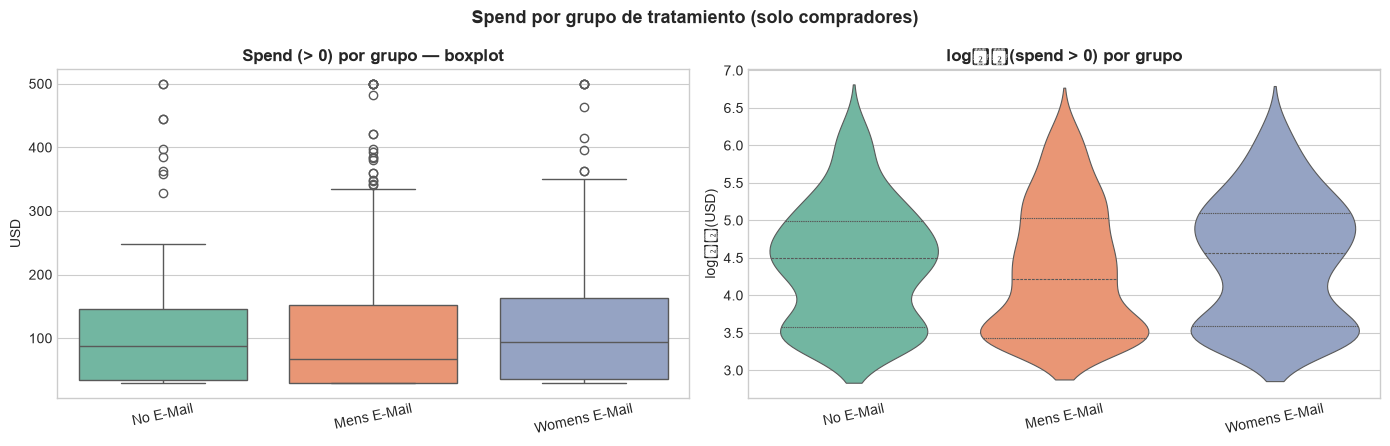

Kruskal-Wallis (diferencia de mediana de spend entre grupos):
  H = 3.0515,  p = 0.217455
  → Sin diferencia significativa entre grupos (α=0.05)


In [14]:
df_nz = df[df["spend"] > 0].copy()
df_nz["log_spend"] = np.log1p(df_nz["spend"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.boxplot(data=df_nz, x="segment", y="spend",
            order=ORDER, palette="Set2", ax=axes[0])
axes[0].set_title("Spend (> 0) por grupo — boxplot", fontsize=12, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("USD")
axes[0].tick_params(axis="x", rotation=12)

sns.violinplot(data=df_nz, x="segment", y="log_spend",
               order=ORDER, palette="Set2", ax=axes[1], inner="quartile", linewidth=0.8)
axes[1].set_title("log₁₊(spend > 0) por grupo", fontsize=12, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("log₁₊(USD)")
axes[1].tick_params(axis="x", rotation=12)

plt.suptitle("Spend por grupo de tratamiento (solo compradores)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Test de Kruskal-Wallis
groups_spend = [df_nz.loc[df_nz["segment"]==s, "spend"].values for s in ORDER]
stat, pval_kw = stats.kruskal(*groups_spend)
print(f"Kruskal-Wallis (diferencia de mediana de spend entre grupos):")
print(f"  H = {stat:.4f},  p = {pval_kw:.6f}")
print(f"  → {'Diferencia significativa' if pval_kw < 0.05 else 'Sin diferencia significativa'} entre grupos (α=0.05)")

## 8. Correlación entre Targets

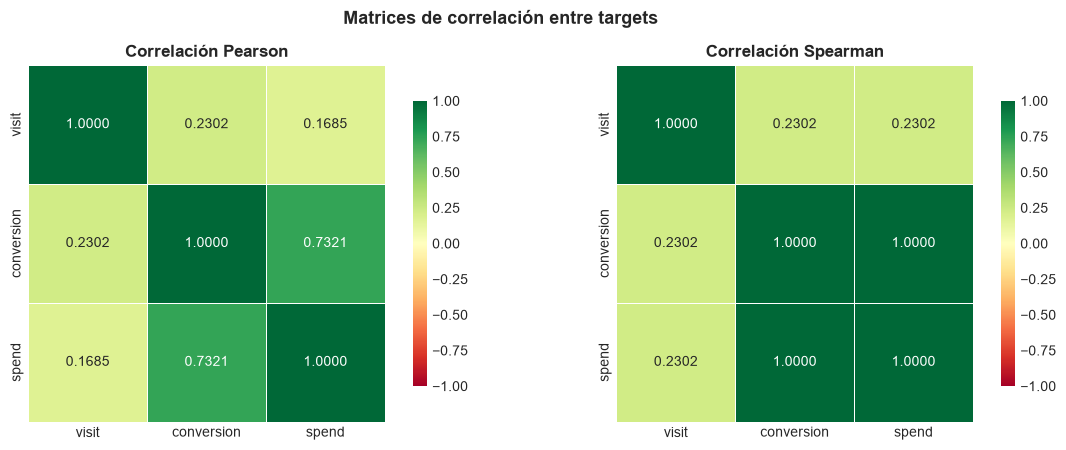

Comentarios:
  Pearson  visit ↔ conversion : 0.2302
  Pearson  conversion ↔ spend : 0.7321
  Spearman visit ↔ spend      : 0.2302

  → conversion y spend tienen correlación perfecta en el subconjunto spend>0.
  → visit↔conversion también es muy alta porque conversion ⊆ visit.


In [15]:
tgt_cols = ["visit", "conversion", "spend"]
pearson  = df[tgt_cols].corr(method="pearson")
spearman = df[tgt_cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, corr, method in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    sns.heatmap(corr, annot=True, fmt=".4f", cmap="RdYlGn",
                center=0, vmin=-1, vmax=1, ax=ax,
                linewidths=0.5, cbar_kws={"shrink":0.8}, square=True)
    ax.set_title(f"Correlación {method}", fontsize=12, fontweight="bold")
plt.suptitle("Matrices de correlación entre targets", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

print("Comentarios:")
print(f"  Pearson  visit ↔ conversion : {pearson.loc['visit','conversion']:.4f}")
print(f"  Pearson  conversion ↔ spend : {pearson.loc['conversion','spend']:.4f}")
print(f"  Spearman visit ↔ spend      : {spearman.loc['visit','spend']:.4f}")
print()
print("  → conversion y spend tienen correlación perfecta en el subconjunto spend>0.")
print("  → visit↔conversion también es muy alta porque conversion ⊆ visit.")

## 9. Síntesis Ejecutiva

In [16]:
print("═"*65)
print("  SÍNTESIS — TARGETS")
print("═"*65)
items = [
    ("visit rate global",            f"{df['visit'].mean()*100:.2f}%  ({df['visit'].sum():,} clientes)"),
    ("conversion rate global",       f"{df['conversion'].mean()*100:.2f}%  ({df['conversion'].sum():,} clientes)"),
    ("P(conv | visit=1)",            f"{df[df['visit']==1]['conversion'].mean()*100:.2f}%"),
    ("spend = 0 (sin compra)",       f"{(df['spend']==0).sum():,}  ({(df['spend']==0).mean()*100:.2f}%)"),
    ("spend > 0 (compradores)",      f"{(df['spend']>0).sum():,}  ({(df['spend']>0).mean()*100:.2f}%)"),
    ("spend mediana (compradores)",  f"${df.loc[df['spend']>0,'spend'].median():.2f} USD"),
    ("spend media (compradores)",    f"${df.loc[df['spend']>0,'spend'].mean():.2f} USD"),
    ("spend máximo",                 f"${df['spend'].max():,.2f} USD"),
    ("Desbalance visit",             f"{n_v0/n_v1:.1f}:1"),
    ("Desbalance conversion",        f"{n_c0/n_c1:.0f}:1  — desbalance severo"),
    ("Emails best visit segment",    f"{seg_p['visit_rate_%'].idxmax()} ({seg_p['visit_rate_%'].max():.2f}%)"),
    ("Emails best conv segment",     f"{seg_p['conv_rate_%'].idxmax()} ({seg_p['conv_rate_%'].max():.2f}%)"),
    ("Naturaleza de spend",          "Zero-inflated — modelo Hurdle recomendado"),
    ("Jerarquía targets",            "spend>0 ⊆ conversion=1 ⊆ visit=1  (100% consistente)"),
]
for k, v in items:
    print(f"  {k:<35}: {v}")
print("═"*65)

═════════════════════════════════════════════════════════════════
  SÍNTESIS — TARGETS
═════════════════════════════════════════════════════════════════
  visit rate global                  : 14.68%  (9,394 clientes)
  conversion rate global             : 0.90%  (578 clientes)
  P(conv | visit=1)                  : 6.15%
  spend = 0 (sin compra)             : 63,422  (99.10%)
  spend > 0 (compradores)            : 578  (0.90%)
  spend mediana (compradores)        : $80.80 USD
  spend media (compradores)          : $116.36 USD
  spend máximo                       : $499.00 USD
  Desbalance visit                   : 5.8:1
  Desbalance conversion              : 110:1  — desbalance severo
  Emails best visit segment          : Mens E-Mail (18.28%)
  Emails best conv segment           : Mens E-Mail (1.25%)
  Naturaleza de spend                : Zero-inflated — modelo Hurdle recomendado
  Jerarquía targets                  : spend>0 ⊆ conversion=1 ⊆ visit=1  (100% consistente)
══════════════

---
## Conclusión

- **`visit`** y **`conversion`** tienen desbalance de clases significativo; métricas apropiadas: AUC-ROC, Qini coefficient.
- **`spend`** es zero-inflated (~85% ceros): se recomienda modelar como Hurdle (P(spend>0) × E[spend|spend>0]) o directamente con árboles.
- Los grupos de tratamiento muestran diferencias claras en los tres outcomes, validando que el experimento capturó un efecto real de las campañas.
- La jerarquía `spend>0 ⊆ conversion=1 ⊆ visit=1` es perfectamente consistente.

**Siguiente:** `03_numerical_features.ipynb`